3nd Assignment Digital Image Processing

Mounted at /content/drive
Loaded image successfully with shape: (899, 1599)


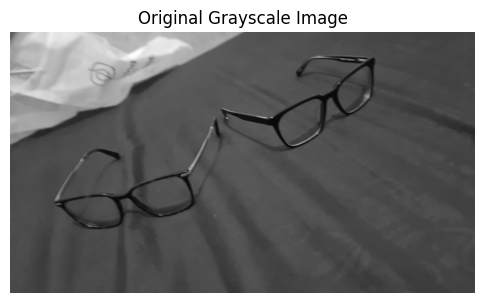

In [21]:
from google.colab import drive
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

drive.mount('/content/drive', force_remount=True)

image_path = '/content/drive/MyDrive/Semester Uni Folders/Semester 3/Segmentation Images/glasses.jpeg'
img_pil = Image.open(image_path)

img_gray = np.array(img_pil.convert('L'))
print(f"Loaded image successfully with shape: {img_gray.shape}")
plt.figure(figsize=(6, 6))
plt.imshow(img_gray, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis('off')
plt.show()

Computed Global Otsu T: 128
Applied Frame Threshold T: 65


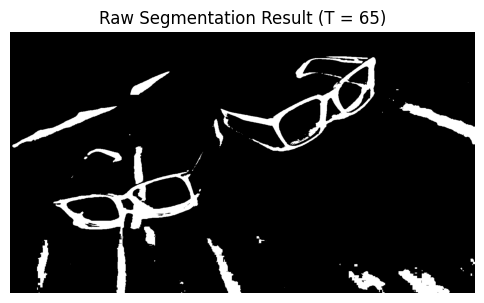

In [22]:
def compute_histogram_scratch(img_2d):
    hist = np.zeros(256, dtype=int)
    for r in range(img_2d.shape[0]):
        for c in range(img_2d.shape[1]):
            val = img_2d[r, c]
            hist[val] += 1
    return hist

def otsu_threshold_scratch(img_2d):
    hist = compute_histogram_scratch(img_2d)
    total_pixels = img_2d.size

    current_max_variance = -1.0
    optimal_threshold = 0

    sum_total = np.sum(np.arange(256) * hist)
    weight_background = 0
    sum_background = 0

    for t in range(256):
        weight_background += hist[t]
        if weight_background == 0:
            continue

        weight_foreground = total_pixels - weight_background
        if weight_foreground == 0:
            break

        sum_background += t * hist[t]

        mean_background = sum_background / weight_background
        mean_foreground = (sum_total - sum_background) / weight_foreground

        between_class_variance = (weight_background * weight_foreground *
                                  ((mean_background - mean_foreground) ** 2))

        if between_class_variance > current_max_variance:
            current_max_variance = between_class_variance
            optimal_threshold = t

    return optimal_threshold

def apply_threshold_scratch(img_2d, threshold):
    binary_img = np.zeros_like(img_2d, dtype=np.uint8)
    for r in range(img_2d.shape[0]):
        for c in range(img_2d.shape[1]):
            if img_2d[r, c] < threshold:
                binary_img[r, c] = 255
            else:
                binary_img[r, c] = 0
    return binary_img

otsu_T = otsu_threshold_scratch(img_gray)
target_T = int(np.percentile(img_gray, 8))

segmented_raw = apply_threshold_scratch(img_gray, target_T)

print(f"Computed Global Otsu T: {otsu_T}")
print(f"Applied Frame Threshold T: {target_T}")

plt.figure(figsize=(6, 6))
plt.imshow(segmented_raw, cmap='gray')
plt.title(f"Raw Segmentation Result (T = {target_T})")
plt.axis('off')
plt.show()

In [23]:
def pad_image_scratch(binary_img, pad_h, pad_w):
    h, w = binary_img.shape
    padded = np.zeros((h + 2 * pad_h, w + 2 * pad_w), dtype=np.uint8)
    padded[pad_h:pad_h + h, pad_w:pad_w + w] = binary_img
    return padded

def dilate_scratch(binary_img, kernel):
    kh, kw = kernel.shape
    pad_h, pad_w = kh // 2, kw // 2
    padded = pad_image_scratch(binary_img, pad_h, pad_w)
    out_img = np.zeros_like(binary_img)

    h, w = binary_img.shape
    for r in range(h):
        for c in range(w):
            region = padded[r:r + kh, c:c + kw]
            if np.any((region == 255) & (kernel == 1)):
                out_img[r, c] = 255
            else:
                out_img[r, c] = 0
    return out_img

def erode_scratch(binary_img, kernel):
    kh, kw = kernel.shape
    pad_h, pad_w = kh // 2, kw // 2
    padded = pad_image_scratch(binary_img, pad_h, pad_w)
    out_img = np.zeros_like(binary_img)

    h, w = binary_img.shape
    for r in range(h):
        for c in range(w):
            region = padded[r:r + kh, c:c + kw]
            if np.all(region[kernel == 1] == 255):
                out_img[r, c] = 255
            else:
                out_img[r, c] = 0
    return out_img

def open_scratch(binary_img, kernel):
    eroded = erode_scratch(binary_img, kernel)
    return dilate_scratch(eroded, kernel)

def close_scratch(binary_img, kernel):
    dilated = dilate_scratch(binary_img, kernel)
    return erode_scratch(dilated, kernel)

struct_elem_3x3 = np.ones((3, 3), dtype=np.uint8)

struct_elem_5x5 = np.ones((5, 5), dtype=np.uint8)

dilated_result = dilate_scratch(segmented_raw, struct_elem_3x3)
eroded_result = erode_scratch(segmented_raw, struct_elem_3x3)
opened_result = open_scratch(segmented_raw, struct_elem_5x5)
closed_result = close_scratch(segmented_raw, struct_elem_3x3)

print("Morphological processing complete!")

Morphological processing complete!


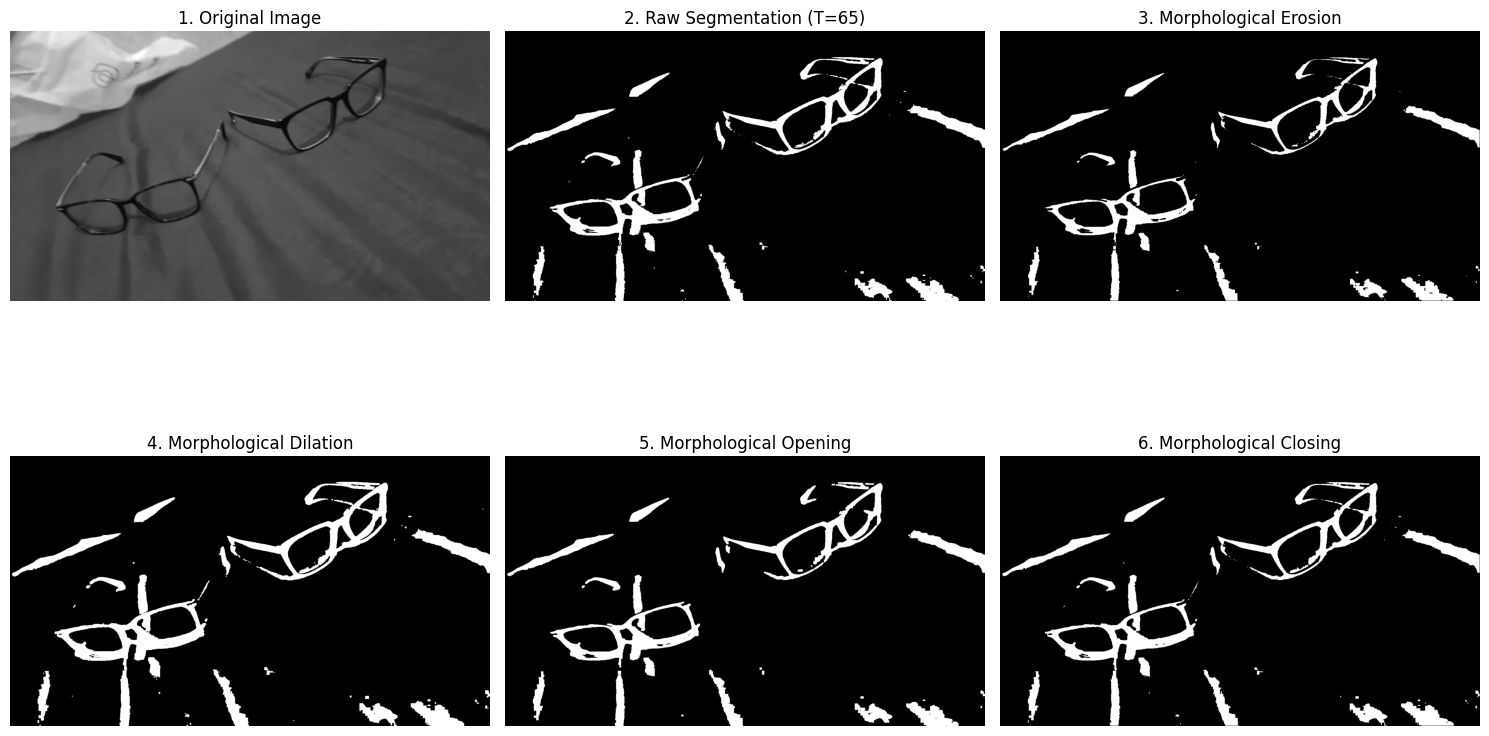

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

axes[0, 0].imshow(img_gray, cmap='gray')
axes[0, 0].set_title("1. Original Image")
axes[0, 0].axis('off')

axes[0, 1].imshow(segmented_raw, cmap='gray')
axes[0, 1].set_title(f"2. Raw Segmentation (T={target_T})")
axes[0, 1].axis('off')

axes[0, 2].imshow(eroded_result, cmap='gray')
axes[0, 2].set_title("3. Morphological Erosion")
axes[0, 2].axis('off')

axes[1, 0].imshow(dilated_result, cmap='gray')
axes[1, 0].set_title("4. Morphological Dilation")
axes[1, 0].axis('off')

axes[1, 1].imshow(opened_result, cmap='gray')
axes[1, 1].set_title("5. Morphological Opening")
axes[1, 1].axis('off')

axes[1, 2].imshow(closed_result, cmap='gray')
axes[1, 2].set_title("6. Morphological Closing")
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

Original image were 2 pairs of glasses placed on top of a bed (a dark coloured one) where in the background also lies a bag. Main goal was to isolate glasses frames with background from bag as well as the also dark color scheme bed sheets with treshholding.

First, applying Otsu algorithm but because image contain non uniform background ligthing, it cause the bedsheet to be a part of one of the glasses because of the treshold.

To refine it then applying 4 different morphological operations:
1. Erosion = Strips surround pixels and so, removes some small isolted noises at a cost of thinning the frames
2. Dilation = Expands foreground regions boundaries. It closes internal void (shown in the left glasses frames are more defined/white when compared to original image)
3. Opening = Filters noise by elimination. It removed some small background noise like in erosion with less/minimal effects to glasses frame thickness, an improvement.
4. Closing: Connecting close disjointed parts (shown by the more define glasses frame)

Conclusion: Comparison with and without post processing indicated that global tresh holding may not always seperate objects from background shadows with similair brightness. Morpholopical processes such as opening and closing can do best of both worlds by cleaning background from noises while preserving original structure